In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

BASE = (
    Path("expirement_v2")
    if Path("expirement_v2/data").is_dir()
    else Path(".")
)

bundle = joblib.load(BASE / "models" / "chl_forecast_1_4_7d.joblib")

predictor_names = bundle["feature_names"]
model_mask = bundle["model_mask"]

print(f"Forecast issue time: {bundle['forecast_issue_time_utc']} UTC")
print(f"Forecast horizons: {bundle['forecast_horizons_days']} days")
print(f"Included grid pixels: {int((model_mask == 1).sum().item()):,}")

display(pd.DataFrame({
    "Input order": range(1, len(predictor_names) + 1),
    "Feature": predictor_names,
}))

Forecast issue time: 20:30 UTC
Forecast horizons: [1, 4, 7] days
Included grid pixels: 12,344


,Input order,Feature
0,1,season_sin
1,2,season_cos
2,3,chl_latest
3,4,chl_age_days
4,5,chl_mean_7d
5,6,chl_observations_7d
6,7,latitude_deg
7,8,longitude_deg
8,9,sst_c
9,10,sst_observed


In [2]:
import copernicusmarine

NRT_DATASETS = {
    "CHL": "cmems_obs-oc_med_bgc-plankton_nrt_l3-multi-1km_P1D",
    "SST": "SST_MED_SST_L3S_NRT_OBSERVATIONS_010_012_a",
}

nrt_metadata = {}
NRT_VERSIONS = {}
rows = []

for source, dataset_id in NRT_DATASETS.items():
    catalogue = copernicusmarine.describe(dataset_id=dataset_id)

    dataset = next(
        dataset
        for product in catalogue.products
        for dataset in product.datasets
        if dataset.dataset_id == dataset_id
    )

    nrt_metadata[source] = dataset
    NRT_VERSIONS[source] = dataset.versions[0].label

    rows.append({
        "Source": source,
        "Dataset ID": dataset_id,
        "Default version": NRT_VERSIONS[source],
    })

display(pd.DataFrame(rows).set_index("Source"))

Fetching catalogue 1:  50%|█████     | 1/2 [00:00<00:00,  1.05it/s]


Fetching catalogue 1: 100%|██████████| 2/2 [00:00<00:00,  2.01it/s]


,Dataset ID,Default version
Source,,
CHL,cmems_obs-oc_med_bgc-plankton_nrt_l3-multi-1km...,202211
SST,SST_MED_SST_L3S_NRT_OBSERVATIONS_010_012_a,202311


In [3]:
NRT_VARIABLES = {
    "CHL": "CHL",
    "SST": "adjusted_sea_surface_temperature",
}

nrt_remote = {}
rows = []

for source, dataset_id in NRT_DATASETS.items():
    margin = 0.07 if source == "SST" else 0.0

    ds = copernicusmarine.open_dataset(
        dataset_id=dataset_id,
        dataset_version=NRT_VERSIONS[source],
        variables=[NRT_VARIABLES[source]],
        minimum_longitude=13.90 - margin,
        maximum_longitude=15.20 + margin,
        minimum_latitude=35.55 - margin,
        maximum_latitude=36.90 + margin,
    )

    # Standardize coordinate names.
    ds = ds.rename({
        old: new
        for old, new in [
            ("lat", "latitude"),
            ("lon", "longitude"),
        ]
        if old in ds.coords and new not in ds.coords
    })

    nrt_remote[source] = ds
    times = pd.DatetimeIndex(ds.time.values)

    rows.append({
        "Source": source,
        "Time labels": len(times),
        "First timestamp": str(times.min()),
        "Latest timestamp": str(times.max()),
        "Latitude cells": ds.sizes["latitude"],
        "Longitude cells": ds.sizes["longitude"],
        "Latitude spacing (°)": float(
            np.median(np.abs(np.diff(ds.latitude.values)))
        ),
        "Longitude spacing (°)": float(
            np.median(np.abs(np.diff(ds.longitude.values)))
        ),
        "Units": ds[NRT_VARIABLES[source]].attrs.get("units", "Not provided"),
    })

display(pd.DataFrame(rows).set_index("Source"))

INFO - 2026-10-07T09:30:09Z - Selected dataset version: "202211"
INFO - 2026-10-07T09:30:09Z - Selected dataset part: "default"
INFO - 2026-10-07T09:30:16Z - Selected dataset version: "202311"
INFO - 2026-10-07T09:30:16Z - Selected dataset part: "default"
Fetching catalogue 1: 100%|██████████| 2/2 [08:48<00:00, 264.07s/it]


,Time labels,First timestamp,Latest timestamp,Latitude cells,Longitude cells,Latitude spacing (°),Longitude spacing (°),Units
Source,,,,,,,,
CHL,15,2026-09-22 00:00:00,2026-10-06 00:00:00,133,101,0.010128,0.012848,milligram m^-3
SST,6855,2008-01-01 00:00:00,2026-10-07 00:00:00,24,23,0.062500,0.062500,kelvin


In [4]:
latest_chl = pd.Timestamp(nrt_remote["CHL"].time.max().values).normalize()
latest_sst = pd.Timestamp(nrt_remote["SST"].time.max().values).normalize()

chl_lag = int(bundle["preprocessing"]["chl_availability_lag_days"])
sst_lag = int(bundle["preprocessing"]["sst_availability_lag_days"])

issue_day = min(
    latest_chl + pd.Timedelta(days=chl_lag),
    latest_sst + pd.Timedelta(days=sst_lag),
)
ISSUE_DATE = issue_day.strftime("%Y-%m-%d")

chl_cutoff = issue_day - pd.Timedelta(days=chl_lag)
sst_date = issue_day - pd.Timedelta(days=sst_lag)

retrieval_started_utc = pd.Timestamp.now(tz="UTC")

nrt_chl_raw = (
    nrt_remote["CHL"]
    .sel(time=slice(None, chl_cutoff))
    .sortby("time")
    .load()
)

nrt_sst_raw = (
    nrt_remote["SST"]
    .sel(time=[sst_date])
    .load()
)

retrieval_finished_utc = pd.Timestamp.now(tz="UTC")

print(f"Nominal forecast issue: {ISSUE_DATE} at 20:30 UTC")
print(
    f"CHL history: {pd.Timestamp(nrt_chl_raw.time.min().values):%Y-%m-%d}"
    f" to {pd.Timestamp(nrt_chl_raw.time.max().values):%Y-%m-%d}"
    f" ({nrt_chl_raw.sizes['time']} days)"
)
print(f"SST date: {sst_date:%Y-%m-%d}")
print(f"Retrieval completed: {retrieval_finished_utc.isoformat()}")

Nominal forecast issue: 2026-10-07 at 20:30 UTC
CHL history: 2026-09-22 to 2026-10-06 (15 days)
SST date: 2026-10-07
Retrieval completed: 2026-10-07T10:04:39.217764+00:00


In [5]:
snapshot_dir = (
    BASE / "data" / "raw" / "nrt_validation"
    / retrieval_finished_utc.strftime("%Y%m%dT%H%M%SZ")
)
snapshot_dir.mkdir(parents=True, exist_ok=True)

for source, dataset in [
    ("CHL", nrt_chl_raw),
    ("SST", nrt_sst_raw),
]:
    saved = dataset.copy()

    saved.attrs.update({
        "source_dataset_id": NRT_DATASETS[source],
        "source_dataset_version": NRT_VERSIONS[source],
        "retrieval_started_utc": retrieval_started_utc.isoformat(),
        "retrieval_finished_utc": retrieval_finished_utc.isoformat(),
        "nominal_issue_date": ISSUE_DATE,
        "nominal_issue_time_utc": bundle["forecast_issue_time_utc"],
    })

    path = snapshot_dir / f"{source.lower()}_nrt.nc"

    saved.to_netcdf(
        path,
        encoding={
            name: {"zlib": True, "complevel": 4}
            for name in saved.data_vars
        },
    )

    print(f"Saved: {path}")

Saved: data\raw\nrt_validation\20261007T100439Z\chl_nrt.nc
Saved: data\raw\nrt_validation\20261007T100439Z\sst_nrt.nc


In [6]:
chl = (
    nrt_chl_raw["CHL"]
    .sortby("latitude")
    .sortby("longitude")
)

# Allow small differences caused by coordinate storage precision.
for coord in ["latitude", "longitude"]:
    matches = (
        chl.sizes[coord] == model_mask.sizes[coord]
        and np.allclose(
            chl[coord].values,
            model_mask[coord].values,
            atol=1e-5,
            rtol=0,
        )
    )
    assert matches, f"NRT CHL {coord} does not match the model grid."

nrt_chl_grid = chl.assign_coords(
    latitude=model_mask.latitude,
    longitude=model_mask.longitude,
).rename("chl")

sst_native = (
    nrt_sst_raw["adjusted_sea_surface_temperature"]
    .sortby("latitude")
    .sortby("longitude")
)

assert sst_native.attrs.get("units", "").lower() in {"kelvin", "k"}

lat_tolerance = 0.51 * float(
    np.median(np.diff(sst_native.latitude.values))
)
lon_tolerance = 0.51 * float(
    np.median(np.diff(sst_native.longitude.values))
)

nrt_sst_grid = (
    (sst_native - 273.15)
    .reindex(
        latitude=model_mask.latitude,
        method="nearest",
        tolerance=lat_tolerance,
    )
    .reindex(
        longitude=model_mask.longitude,
        method="nearest",
        tolerance=lon_tolerance,
    )
    .rename("sst_c")
)
nrt_sst_grid.attrs["units"] = "degree_Celsius"

rows = []
for source, field in [("CHL", nrt_chl_grid), ("SST", nrt_sst_grid)]:
    rows.append({
        "Source": source,
        "Latitude cells": field.sizes["latitude"],
        "Longitude cells": field.sizes["longitude"],
        "Coordinates match model": (
            field.latitude.equals(model_mask.latitude)
            and field.longitude.equals(model_mask.longitude)
        ),
        "Units": field.attrs.get("units", "Not provided"),
    })

display(pd.DataFrame(rows).set_index("Source"))

,Latitude cells,Longitude cells,Coordinates match model,Units
Source,,,,
CHL,133,101,True,milligram m^-3
SST,133,101,True,degree_Celsius


In [7]:
chl_history = nrt_chl_grid.transpose(
    "time", "latitude", "longitude"
).where(model_mask == 1)

assert pd.Timestamp(chl_history.time.max().values) <= chl_cutoff

values = chl_history.values
valid = np.isfinite(values) & (values > 0)

time_index = np.arange(values.shape[0])[:, None, None]
last_index = np.max(np.where(valid, time_index, -1), axis=0)

has_history = last_index >= 0
safe_index = np.maximum(last_index, 0)

latest_chl = np.take_along_axis(
    values, safe_index[None, :, :], axis=0
)[0]

latest_dates = chl_history.time.values[safe_index]
age_days = (
    issue_day.to_datetime64() - latest_dates
) / np.timedelta64(1, "D")

nrt_features = xr.Dataset(
    {
        "chl_latest": (
            ("latitude", "longitude"),
            np.where(has_history, latest_chl, np.nan).astype("float32"),
        ),
        "chl_age_days": (
            ("latitude", "longitude"),
            np.where(has_history, age_days, np.nan).astype("float32"),
        ),
    },
    coords={
        "latitude": model_mask.latitude,
        "longitude": model_mask.longitude,
        "time": issue_day.to_datetime64(),
    },
)

included = model_mask.values == 1

display(pd.Series({
    "Included pixels": int(included.sum()),
    "Pixels with CHL history": int((included & has_history).sum()),
    "Pixels without CHL history": int((included & ~has_history).sum()),
    "Minimum CHL age (days)": float(nrt_features.chl_age_days.min()),
    "Maximum CHL age (days)": float(nrt_features.chl_age_days.max()),
}).to_frame("Value"))

,Value
Included pixels,12344.0
Pixels with CHL history,12245.0
Pixels without CHL history,99.0
Minimum CHL age (days),1.0
Maximum CHL age (days),14.0


In [8]:
history_days = int(bundle["preprocessing"]["chl_history_window_days"])
window_start = chl_cutoff - pd.Timedelta(days=history_days - 1)

chl_window = (
    chl_history
    .sel(time=slice(window_start, chl_cutoff))
    .where(chl_history > 0)
)

nrt_features["chl_mean_7d"] = (
    chl_window.mean("time", skipna=True).astype("float32")
)

nrt_features["chl_observations_7d"] = (
    chl_window.count("time").astype("float32")
)

counts = nrt_features["chl_observations_7d"].where(model_mask == 1)

print(
    f"CHL averaging window: {window_start:%Y-%m-%d}"
    f" to {chl_cutoff:%Y-%m-%d}"
)

display(pd.Series({
    "Pixels with at least one observation":
        int((counts > 0).sum().item()),
    "Pixels with no observations":
        int((counts == 0).sum().item()),
    "Minimum observations per pixel": float(counts.min().item()),
    "Maximum observations per pixel": float(counts.max().item()),
    "Mean observations per pixel": float(counts.mean().item()),
}).to_frame("Value"))

CHL averaging window: 2026-09-30 to 2026-10-06


,Value
Pixels with at least one observation,12207.000000
Pixels with no observations,137.000000
Minimum observations per pixel,0.000000
Maximum observations per pixel,7.000000
Mean observations per pixel,5.835872


In [9]:
sst_today = nrt_sst_grid.sel(
    time=sst_date, drop=True
).where(model_mask == 1)

nrt_features["sst_c"] = sst_today.astype("float32")
nrt_features["sst_observed"] = (
    np.isfinite(sst_today).astype("float32")
)

# Match the seasonal encoding used during training.
days_in_year = 366 if issue_day.is_leap_year else 365
phase = 2 * np.pi * (issue_day.dayofyear - 1) / days_in_year

nrt_features["season_sin"] = np.float32(np.sin(phase))
nrt_features["season_cos"] = np.float32(np.cos(phase))

nrt_features["latitude_deg"] = model_mask.latitude.astype("float32")
nrt_features["longitude_deg"] = model_mask.longitude.astype("float32")

# Preserve the exact input order expected by the saved models.
nrt_features = nrt_features[predictor_names]

nrt_features.attrs.update({
    "time_meaning": "Forecast issue date",
    "forecast_issue_time_utc": bundle["forecast_issue_time_utc"],
    "retrieval_finished_utc": retrieval_finished_utc.isoformat(),
    "chl_latest_eligible_date": chl_cutoff.strftime("%Y-%m-%d"),
    "sst_date": sst_date.strftime("%Y-%m-%d"),
})

sst_valid_pixels = int(
    (np.isfinite(sst_today) & (model_mask == 1)).sum().item()
)
included_pixels = int((model_mask == 1).sum().item())

display(pd.Series({
    "Model features": len(nrt_features.data_vars),
    "Included pixels": included_pixels,
    "Pixels with current SST": sst_valid_pixels,
    "SST coverage (%)": 100 * sst_valid_pixels / included_pixels,
    "Minimum SST (°C)": float(sst_today.min().item()),
    "Maximum SST (°C)": float(sst_today.max().item()),
}).to_frame("Value"))

,Value
Model features,10.000000
Included pixels,12344.000000
Pixels with current SST,11936.000000
SST coverage (%),96.694750
Minimum SST (°C),24.799993
Maximum SST (°C),26.569993


In [10]:
mask = model_mask.values == 1
lat_idx, lon_idx = np.nonzero(mask)
horizons = bundle["forecast_horizons_days"]

X_nrt = (
    nrt_features.isel(
        latitude=xr.DataArray(lat_idx, dims="pixel"),
        longitude=xr.DataArray(lon_idx, dims="pixel"),
    )
    .drop_vars(["time", "latitude", "longitude"])
    .to_dataframe()[predictor_names]
    .astype("float32")
)

values = np.full(
    (len(horizons), *mask.shape), np.nan, dtype="float32"
)

for i, horizon in enumerate(horizons):
    prediction = 10.0 ** bundle["models"][horizon].predict(X_nrt)

    assert np.all(np.isfinite(prediction) & (prediction > 0))

    values[i, lat_idx, lon_idx] = prediction

nrt_forecast = xr.Dataset(
    {
        "chl_forecast": (
            ("horizon", "latitude", "longitude"),
            values,
        ),
        "chl_history_available":
            np.isfinite(nrt_features["chl_latest"]).astype("uint8"),
        "sst_available":
            np.isfinite(nrt_features["sst_c"]).astype("uint8"),
        "model_mask": model_mask.astype("uint8"),
    },
    coords={
        "horizon": horizons,
        "latitude": model_mask.latitude,
        "longitude": model_mask.longitude,
        "time": issue_day.to_datetime64(),
        "target_date": (
            "horizon",
            [
                (issue_day + pd.Timedelta(days=int(h))).to_datetime64()
                for h in horizons
            ],
        ),
    },
    attrs={
        "issue_date": ISSUE_DATE,
        "nominal_issue_time_utc": bundle["forecast_issue_time_utc"],
        "retrieval_finished_utc": retrieval_finished_utc.isoformat(),
        "input_source": "Copernicus Marine NRT observations",
        "model_training_source": "Copernicus Marine MY observations",
    },
)

nrt_forecast["chl_forecast"].attrs["units"] = bundle["target_units"]

display(pd.DataFrame({
    "Horizon": [f"+{h}d" for h in horizons],
    "Target date": nrt_forecast.target_date.to_index().strftime("%Y-%m-%d"),
    "Forecast pixels": np.isfinite(values).sum(axis=(1, 2)),
}).set_index("Horizon"))

,Target date,Forecast pixels
Horizon,,
+1d,2026-10-08,12344
+4d,2026-10-11,12344
+7d,2026-10-14,12344


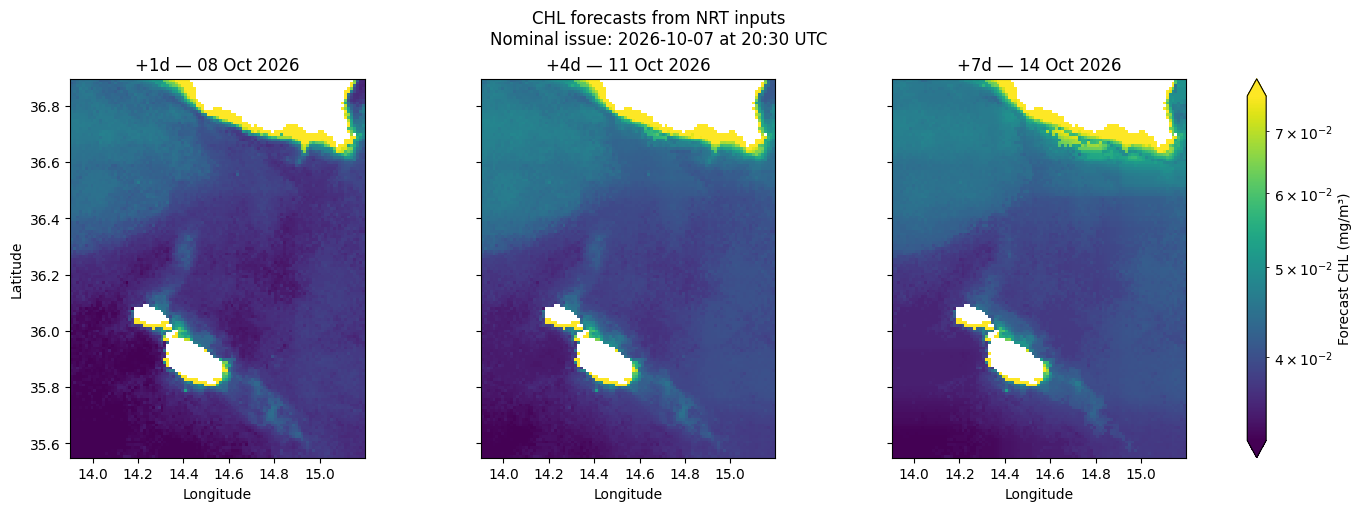

In [11]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

field = nrt_forecast["chl_forecast"]

vmin, vmax = np.nanpercentile(field.values, [2, 98])
norm = LogNorm(vmin=vmin, vmax=vmax)

fig, axes = plt.subplots(
    1, 3, figsize=(14, 5),
    sharex=True, sharey=True,
    constrained_layout=True,
)

for ax, horizon, target_date in zip(
    axes,
    nrt_forecast.horizon.values,
    nrt_forecast.target_date.to_index(),
):
    image = field.sel(horizon=horizon).plot.pcolormesh(
        ax=ax,
        x="longitude",
        y="latitude",
        cmap="viridis",
        norm=norm,
        add_colorbar=False,
    )

    ax.set_title(f"+{int(horizon)}d — {target_date:%d %b %Y}")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude" if ax is axes[0] else "")
    ax.set_aspect(
        1 / np.cos(np.deg2rad(float(model_mask.latitude.mean())))
    )

fig.colorbar(
    image,
    ax=axes.tolist(),
    label="Forecast CHL (mg/m³)",
    extend="both",
)

fig.suptitle(
    f"CHL forecasts from NRT inputs\n"
    f"Nominal issue: {ISSUE_DATE} at "
    f"{bundle['forecast_issue_time_utc']} UTC"
)

plt.show()

In [12]:
import json

forecast_dir = (
    BASE / "data" / "processed" / "nrt_forecasts"
    / snapshot_dir.name
)
forecast_dir.mkdir(parents=True, exist_ok=True)

provenance = {
    "source_datasets_json": json.dumps(NRT_DATASETS),
    "source_versions_json": json.dumps(NRT_VERSIONS),
    "feature_names_json": json.dumps(predictor_names),
    "model_file": "chl_forecast_1_4_7d.joblib",
    "raw_snapshot_directory": str(snapshot_dir),
    "retrieval_finished_utc": retrieval_finished_utc.isoformat(),
}

features_to_save = nrt_features.copy()
features_to_save.attrs.update(provenance)

forecast_to_save = nrt_forecast.copy()
forecast_to_save.attrs.update(provenance)

for filename, dataset in [
    ("nrt_features.nc", features_to_save),
    ("chl_forecasts.nc", forecast_to_save),
]:
    dataset.to_netcdf(
        forecast_dir / filename,
        encoding={
            name: {"zlib": True, "complevel": 4}
            for name, variable in dataset.data_vars.items()
            if variable.ndim > 0
        },
    )

fig.savefig(
    forecast_dir / "chl_forecasts.png",
    dpi=200,
    bbox_inches="tight",
)

print(f"Saved inputs, forecasts and figure to: {forecast_dir.resolve()}")

Saved inputs, forecasts and figure to: C:\GIT\mcast.pages.chloropyll_prediction_v2\experiment_v2\data\processed\nrt_forecasts\20261007T100439Z


In [15]:
latest_chl_date = pd.Timestamp(
    nrt_remote["CHL"].time.max().values
).normalize()

retro_issue_day = latest_chl_date - pd.Timedelta(
    days=int(max(bundle["forecast_horizons_days"]))
)

RETRO_ISSUE_DATE = retro_issue_day.strftime("%Y-%m-%d")
retro_chl_cutoff = retro_issue_day - pd.Timedelta(days=chl_lag)
retro_sst_date = retro_issue_day - pd.Timedelta(days=sst_lag)

retro_chl_raw = (
    nrt_remote["CHL"]
    .sel(time=slice(None, retro_chl_cutoff))
    .sortby("time")
    .load()
)

retro_sst_raw = (
    nrt_remote["SST"]
    .sel(time=[retro_sst_date])
    .load()
)

required_start = retro_chl_cutoff - pd.Timedelta(
    days=int(bundle["preprocessing"]["chl_history_window_days"]) - 1
)

assert pd.Timestamp(retro_chl_raw.time.min().values) <= required_start, (
    "Insufficient CHL history for the seven-day feature window."
)

print(f"Retrospective issue date: {RETRO_ISSUE_DATE}")
print(
    f"CHL history: {pd.Timestamp(retro_chl_raw.time.min().values):%Y-%m-%d}"
    f" to {retro_chl_cutoff:%Y-%m-%d}"
)
print(f"SST date: {retro_sst_date:%Y-%m-%d}")

display(pd.DataFrame({
    "Horizon": [
        f"+{h}d" for h in bundle["forecast_horizons_days"]
    ],
    "Target date": [
        (retro_issue_day + pd.Timedelta(days=int(h))).strftime("%Y-%m-%d")
        for h in bundle["forecast_horizons_days"]
    ],
}).set_index("Horizon"))

Retrospective issue date: 2026-09-29
CHL history: 2026-09-22 to 2026-09-28
SST date: 2026-09-29


,Target date
Horizon,
+1d,2026-09-30
+4d,2026-10-03
+7d,2026-10-06


In [16]:
retro_chl = (
    retro_chl_raw["CHL"]
    .sortby("latitude")
    .sortby("longitude")
)

for coord in ["latitude", "longitude"]:
    assert (
        retro_chl.sizes[coord] == model_mask.sizes[coord]
        and np.allclose(
            retro_chl[coord].values,
            model_mask[coord].values,
            atol=1e-5,
            rtol=0,
        )
    ), f"Retrospective CHL {coord} differs from the model grid."

retro_chl_grid = (
    retro_chl.assign_coords(
        latitude=model_mask.latitude,
        longitude=model_mask.longitude,
    )
    .where(model_mask == 1)
    .rename("chl")
)

retro_sst_native = (
    retro_sst_raw["adjusted_sea_surface_temperature"]
    .sortby("latitude")
    .sortby("longitude")
)

assert retro_sst_native.attrs.get("units", "").lower() in {"kelvin", "k"}

retro_sst_grid = (
    (retro_sst_native - 273.15)
    .reindex(
        latitude=model_mask.latitude,
        method="nearest",
        tolerance=lat_tolerance,
    )
    .reindex(
        longitude=model_mask.longitude,
        method="nearest",
        tolerance=lon_tolerance,
    )
    .where(model_mask == 1)
    .rename("sst_c")
)
retro_sst_grid.attrs["units"] = "degree_Celsius"

display(pd.Series({
    "CHL history days": retro_chl_grid.sizes["time"],
    "SST date": retro_sst_date.strftime("%Y-%m-%d"),
    "Pixels with SST": int(np.isfinite(retro_sst_grid).sum().item()),
    "Minimum SST (°C)": float(retro_sst_grid.min().item()),
    "Maximum SST (°C)": float(retro_sst_grid.max().item()),
}).to_frame("Value"))

,Value
CHL history days,7
SST date,2026-09-29
Pixels with SST,12029
Minimum SST (°C),24.859993
Maximum SST (°C),27.219993


In [17]:
history = retro_chl_grid.transpose(
    "time", "latitude", "longitude"
)
history = history.where(np.isfinite(history) & (history > 0))

values = history.values
valid = np.isfinite(values)
time_index = np.arange(values.shape[0])[:, None, None]

last_index = np.max(np.where(valid, time_index, -1), axis=0)
has_history = last_index >= 0
safe_index = np.maximum(last_index, 0)

latest_values = np.take_along_axis(
    values, safe_index[None, :, :], axis=0
)[0]

latest_dates = history.time.values[safe_index]
age_days = (
    retro_issue_day.to_datetime64() - latest_dates
) / np.timedelta64(1, "D")

window_start = retro_chl_cutoff - pd.Timedelta(days=history_days - 1)
window = history.sel(time=slice(window_start, retro_chl_cutoff))

sst = retro_sst_grid.sel(time=retro_sst_date, drop=True)

days_in_year = 366 if retro_issue_day.is_leap_year else 365
phase = 2 * np.pi * (retro_issue_day.dayofyear - 1) / days_in_year

retro_features = xr.Dataset(
    {
        "chl_latest": (
            ("latitude", "longitude"),
            np.where(has_history, latest_values, np.nan).astype("float32"),
        ),
        "chl_age_days": (
            ("latitude", "longitude"),
            np.where(has_history, age_days, np.nan).astype("float32"),
        ),
        "chl_mean_7d": window.mean("time", skipna=True).astype("float32"),
        "chl_observations_7d": window.count("time").astype("float32"),
        "sst_c": sst.astype("float32"),
        "sst_observed": np.isfinite(sst).astype("float32"),
        "season_sin": np.float32(np.sin(phase)),
        "season_cos": np.float32(np.cos(phase)),
        "latitude_deg": model_mask.latitude.astype("float32"),
        "longitude_deg": model_mask.longitude.astype("float32"),
    },
    coords={"time": retro_issue_day.to_datetime64()},
)[predictor_names]

included = model_mask.values == 1

display(pd.Series({
    "Features": len(retro_features.data_vars),
    "Pixels with CHL history": int((included & has_history).sum()),
    "Pixels without CHL history": int((included & ~has_history).sum()),
    "Minimum CHL age (days)": float(retro_features.chl_age_days.min()),
    "Maximum CHL age (days)": float(retro_features.chl_age_days.max()),
}).to_frame("Value"))

,Value
Features,10.0
Pixels with CHL history,12204.0
Pixels without CHL history,140.0
Minimum CHL age (days),1.0
Maximum CHL age (days),7.0


In [18]:
lat_idx, lon_idx = np.nonzero(model_mask.values == 1)
retro_horizons = bundle["forecast_horizons_days"]

X_retro = (
    retro_features.isel(
        latitude=xr.DataArray(lat_idx, dims="pixel"),
        longitude=xr.DataArray(lon_idx, dims="pixel"),
    )
    .drop_vars(["time", "latitude", "longitude"])
    .to_dataframe()[predictor_names]
    .astype("float32")
)

retro_values = np.full(
    (len(retro_horizons), *model_mask.shape),
    np.nan,
    dtype="float32",
)

for i, horizon in enumerate(retro_horizons):
    prediction = 10.0 ** bundle["models"][horizon].predict(X_retro)
    assert np.all(np.isfinite(prediction) & (prediction > 0))

    retro_values[i, lat_idx, lon_idx] = prediction

retro_forecast = xr.Dataset(
    {
        "chl_forecast": (
            ("horizon", "latitude", "longitude"),
            retro_values,
        ),
    },
    coords={
        "horizon": retro_horizons,
        "latitude": model_mask.latitude,
        "longitude": model_mask.longitude,
        "target_date": (
            "horizon",
            [
                (retro_issue_day + pd.Timedelta(days=int(h))).to_datetime64()
                for h in retro_horizons
            ],
        ),
    },
    attrs={
        "issue_date": RETRO_ISSUE_DATE,
        "nominal_issue_time_utc": bundle["forecast_issue_time_utc"],
        "evaluation_type": "Retrospective using currently retrieved NRT data",
    },
)

retro_forecast["chl_forecast"].attrs["units"] = bundle["target_units"]

display(pd.DataFrame({
    "Horizon": [f"+{h}d" for h in retro_horizons],
    "Target date": retro_forecast.target_date.to_index().strftime("%Y-%m-%d"),
    "Forecast pixels": np.isfinite(retro_values).sum(axis=(1, 2)),
}).set_index("Horizon"))

,Target date,Forecast pixels
Horizon,,
+1d,2026-09-30,12344
+4d,2026-10-03,12344
+7d,2026-10-06,12344


In [19]:
target_dates = retro_forecast.target_date.values

retro_observed = (
    nrt_remote["CHL"]["CHL"]
    .sel(time=target_dates)
    .sortby("latitude")
    .sortby("longitude")
    .load()
)

for coord in ["latitude", "longitude"]:
    assert (
        retro_observed.sizes[coord] == model_mask.sizes[coord]
        and np.allclose(
            retro_observed[coord].values,
            model_mask[coord].values,
            atol=1e-5,
            rtol=0,
        )
    ), f"Observed CHL {coord} differs from the model grid."

retro_observed = (
    retro_observed
    .assign_coords(
        latitude=model_mask.latitude,
        longitude=model_mask.longitude,
    )
    .rename({"time": "horizon"})
    .assign_coords(
        horizon=retro_horizons,
        target_date=("horizon", target_dates),
    )
    .where(model_mask == 1)
    .rename("chl_observed")
)

retro_observed = retro_observed.where(
    np.isfinite(retro_observed) & (retro_observed > 0)
)

observed_counts = retro_observed.notnull().sum(
    ("latitude", "longitude")
).values

included_pixels = int((model_mask == 1).sum().item())

display(pd.DataFrame({
    "Horizon": [f"+{h}d" for h in retro_horizons],
    "Target date": pd.DatetimeIndex(target_dates).strftime("%Y-%m-%d"),
    "Observed pixels": observed_counts,
    "Coverage (%)": 100 * observed_counts / included_pixels,
}).set_index("Horizon").style.format({
    "Observed pixels": "{:,.0f}",
    "Coverage (%)": "{:.1f}",
}))

,Target date,Observed pixels,Coverage (%)
Horizon,,,
+1d,2026-09-30,"5,196",42.1
+4d,2026-10-03,"7,924",64.2
+7d,2026-10-06,"12,118",98.2


In [20]:
def chl_metrics(actual, predicted):
    actual = actual.astype("float64")
    predicted = predicted.astype("float64")

    error = predicted - actual
    log_error = np.log10(predicted / actual)

    return {
        "Scored pixels": len(actual),
        "Bias (mg/m³)": error.mean(),
        "MAE (mg/m³)": np.abs(error).mean(),
        "RMSE (mg/m³)": np.sqrt(np.mean(error**2)),
        "RMSE (log10)": np.sqrt(np.mean(log_error**2)),
        "Median relative error (%)":
            np.median(100 * np.abs(error) / actual),
    }


persistence = retro_features["chl_latest"].transpose(
    "latitude", "longitude"
).values

rows = []

for horizon in retro_horizons:
    actual = retro_observed.sel(horizon=horizon).values
    predicted = retro_forecast["chl_forecast"].sel(horizon=horizon).values

    observed = np.isfinite(actual) & (actual > 0)

    common = (
        observed
        & np.isfinite(predicted) & (predicted > 0)
        & np.isfinite(persistence) & (persistence > 0)
    )

    for method, field in [
        ("Persistence", persistence),
        ("Forecast model", predicted),
    ]:
        rows.append({
            "Horizon": f"+{horizon}d",
            "Method": method,
            **chl_metrics(actual[common], field[common]),
            "Observed targets scored (%)":
                100 * common.sum() / observed.sum(),
        })

retro_scores = pd.DataFrame(rows).set_index(["Horizon", "Method"])

display(retro_scores.style.format({
    "Scored pixels": "{:,.0f}",
    "Observed targets scored (%)": "{:.1f}",
    "Bias (mg/m³)": "{:+.4f}",
    "MAE (mg/m³)": "{:.4f}",
    "RMSE (mg/m³)": "{:.4f}",
    "RMSE (log10)": "{:.4f}",
    "Median relative error (%)": "{:.1f}",
}))

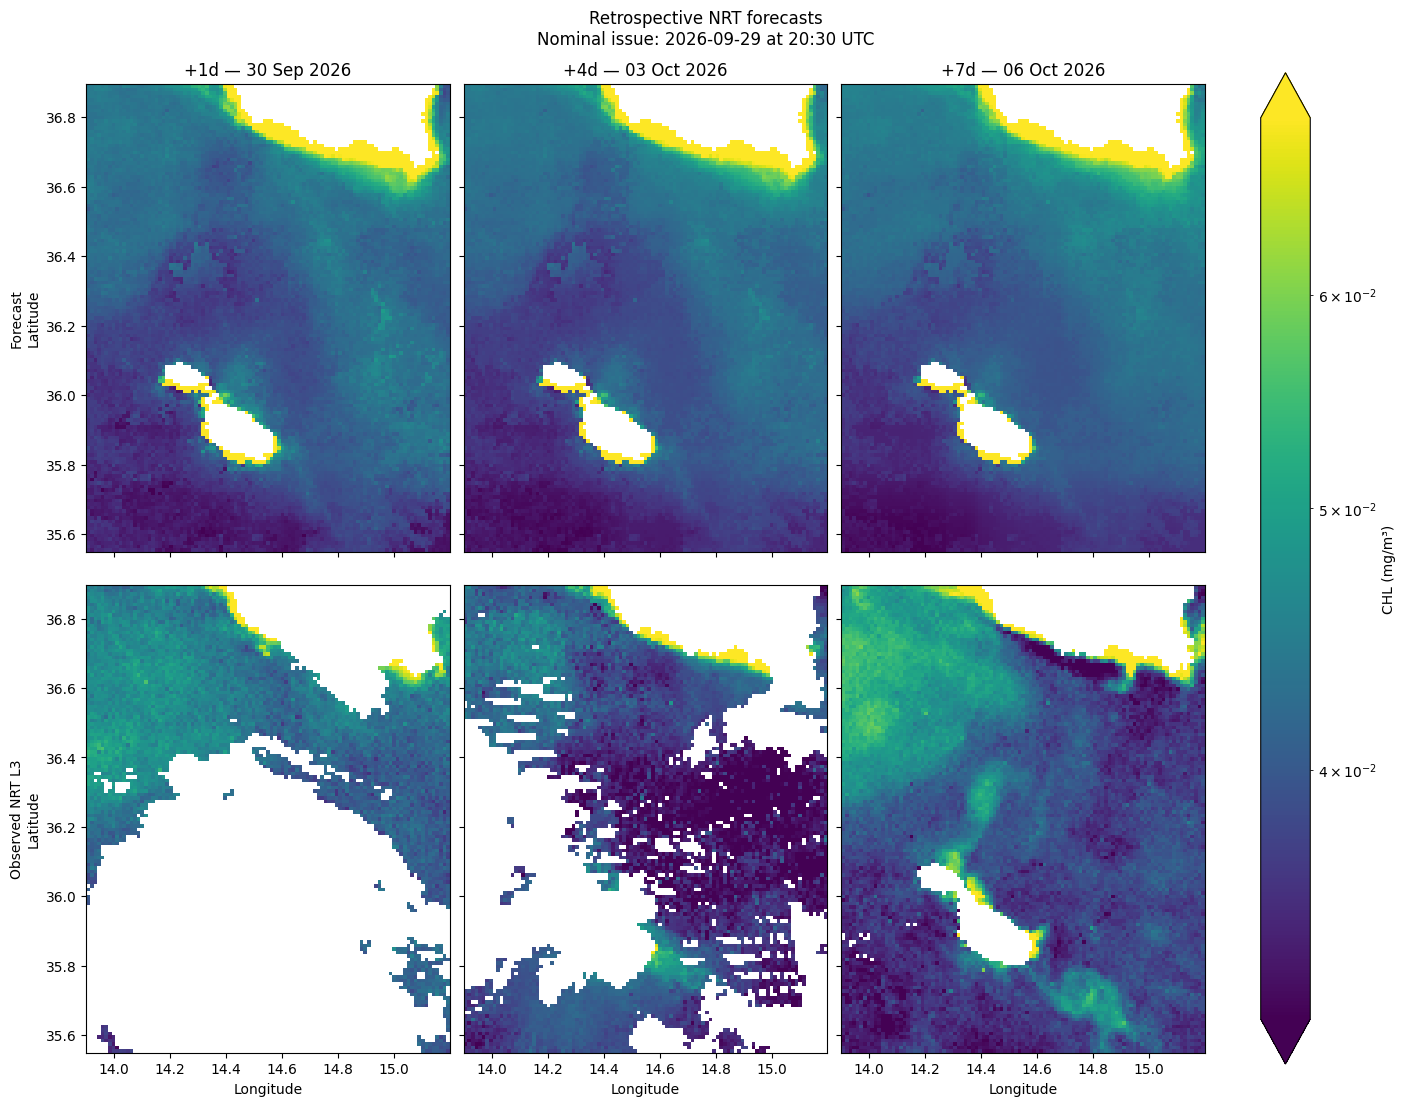

In [21]:
combined_values = np.concatenate([
    retro_forecast["chl_forecast"].values.ravel(),
    retro_observed.values.ravel(),
])

positive = combined_values[
    np.isfinite(combined_values) & (combined_values > 0)
]
vmin, vmax = np.percentile(positive, [2, 98])
retro_norm = LogNorm(vmin=vmin, vmax=vmax)

retro_fig, retro_axes = plt.subplots(
    2, 3, figsize=(14, 11),
    sharex=True, sharey=True,
    constrained_layout=True,
)

for row, (label, field) in enumerate([
    ("Forecast", retro_forecast["chl_forecast"]),
    ("Observed NRT L3", retro_observed),
]):
    for col, (horizon, target_date) in enumerate(zip(
        retro_forecast.horizon.values,
        retro_forecast.target_date.to_index(),
    )):
        ax = retro_axes[row, col]

        image = field.sel(horizon=horizon).plot.pcolormesh(
            ax=ax,
            x="longitude",
            y="latitude",
            cmap="viridis",
            norm=retro_norm,
            add_colorbar=False,
        )

        ax.set_title(
            f"+{int(horizon)}d — {target_date:%d %b %Y}"
            if row == 0 else ""
        )
        ax.set_xlabel("Longitude" if row == 1 else "")
        ax.set_ylabel(f"{label}\nLatitude" if col == 0 else "")
        ax.set_aspect(
            1 / np.cos(np.deg2rad(float(model_mask.latitude.mean())))
        )

retro_fig.colorbar(
    image,
    ax=retro_axes.ravel().tolist(),
    label="CHL (mg/m³)",
    extend="both",
)

retro_fig.suptitle(
    f"Retrospective NRT forecasts\n"
    f"Nominal issue: {RETRO_ISSUE_DATE} at "
    f"{bundle['forecast_issue_time_utc']} UTC"
)

plt.show()

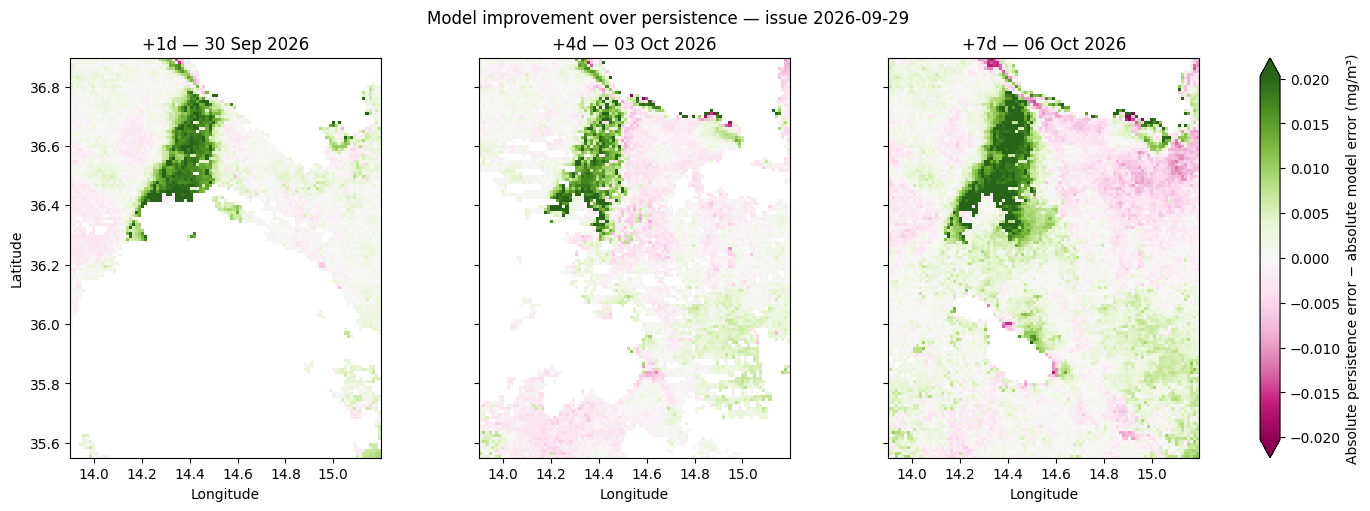

In [22]:
actual = retro_observed
predicted = retro_forecast["chl_forecast"]
baseline = retro_features["chl_latest"]

common = (
    np.isfinite(actual) & (actual > 0)
    & np.isfinite(predicted) & (predicted > 0)
    & np.isfinite(baseline) & (baseline > 0)
)

retro_error_reduction = (
    np.abs(baseline - actual)
    - np.abs(predicted - actual)
).where(common).rename("absolute_error_reduction")

limit = max(
    float(np.nanpercentile(np.abs(retro_error_reduction.values), 98)),
    1e-6,
)

retro_skill_fig, axes = plt.subplots(
    1, 3, figsize=(14, 5),
    sharex=True, sharey=True,
    constrained_layout=True,
)

for ax, horizon, target_date in zip(
    axes,
    retro_forecast.horizon.values,
    retro_forecast.target_date.to_index(),
):
    image = retro_error_reduction.sel(horizon=horizon).plot.pcolormesh(
        ax=ax,
        x="longitude",
        y="latitude",
        cmap="PiYG",
        vmin=-limit,
        vmax=limit,
        add_colorbar=False,
    )

    ax.set_title(f"+{int(horizon)}d — {target_date:%d %b %Y}")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude" if ax is axes[0] else "")
    ax.set_aspect(
        1 / np.cos(np.deg2rad(float(model_mask.latitude.mean())))
    )

retro_skill_fig.colorbar(
    image,
    ax=axes.tolist(),
    label="Absolute persistence error − absolute model error (mg/m³)",
    extend="both",
)

retro_skill_fig.suptitle(
    f"Model improvement over persistence — issue {RETRO_ISSUE_DATE}"
)

plt.show()

In [23]:
import json

saved_utc = pd.Timestamp.now(tz="UTC")

retro_dir = (
    BASE / "data" / "processed" / "nrt_retrospective"
    / RETRO_ISSUE_DATE
    / saved_utc.strftime("%Y%m%dT%H%M%SZ")
)
retro_dir.mkdir(parents=True, exist_ok=True)

evaluation = retro_forecast.assign(
    chl_observed=retro_observed,
    persistence_chl=retro_features["chl_latest"],
    absolute_error_reduction=retro_error_reduction,
    model_mask=model_mask,
)

for name in ["persistence_chl", "absolute_error_reduction"]:
    evaluation[name].attrs["units"] = bundle["target_units"]

provenance = {
    "nominal_issue_date": RETRO_ISSUE_DATE,
    "nominal_issue_time_utc": bundle["forecast_issue_time_utc"],
    "evaluation_type": "Retrospective using currently retrieved NRT data",
    "source_datasets_json": json.dumps(NRT_DATASETS),
    "source_versions_json": json.dumps(NRT_VERSIONS),
    "feature_names_json": json.dumps(predictor_names),
    "model_file": "chl_forecast_1_4_7d.joblib",
    "saved_utc": saved_utc.isoformat(),
}

for filename, dataset in [
    ("chl_history_inputs.nc", retro_chl_raw),
    ("sst_inputs.nc", retro_sst_raw),
    ("features.nc", retro_features),
    ("evaluation.nc", evaluation),
]:
    output = dataset.copy()
    output.attrs.update(provenance)

    output.to_netcdf(
        retro_dir / filename,
        encoding={
            name: {"zlib": True, "complevel": 4}
            for name, variable in output.data_vars.items()
            if variable.ndim > 0
        },
    )

retro_scores.reset_index().to_json(
    retro_dir / "scores.json",
    orient="records",
    indent=2,
    double_precision=10,
)

retro_fig.savefig(
    retro_dir / "forecast_vs_observed.png",
    dpi=200, bbox_inches="tight",
)
retro_skill_fig.savefig(
    retro_dir / "improvement_over_persistence.png",
    dpi=200, bbox_inches="tight",
)

print(f"Saved retrospective evaluation to: {retro_dir.resolve()}")

Saved retrospective evaluation to: C:\GIT\mcast.pages.chloropyll_prediction_v2\experiment_v2\data\processed\nrt_retrospective\2026-09-29\20261007T110431Z


In [24]:
chl_dates = pd.DatetimeIndex(nrt_remote["CHL"].time.values).normalize()
sst_dates = pd.DatetimeIndex(nrt_remote["SST"].time.values).normalize()

history_days = int(bundle["preprocessing"]["chl_history_window_days"])

issue_dates = pd.date_range(
    chl_dates.min() + pd.Timedelta(days=chl_lag),
    chl_dates.max() + pd.Timedelta(days=chl_lag),
    freq="D",
)

rows = []

for issue in issue_dates:
    chl_end = issue - pd.Timedelta(days=chl_lag)

    required_history = pd.date_range(
        chl_end - pd.Timedelta(days=history_days - 1),
        chl_end,
        freq="D",
    )

    available_history_days = len(
        required_history.intersection(chl_dates)
    )

    row = {
        "Issue date": issue.strftime("%Y-%m-%d"),
        "CHL window labels": available_history_days,
        "History window": (
            "Complete"
            if available_history_days == history_days
            else "Partial"
        ),
        "SST label available":
            issue - pd.Timedelta(days=sst_lag) in sst_dates,
    }

    for horizon in bundle["forecast_horizons_days"]:
        target_date = issue + pd.Timedelta(days=int(horizon))
        row[f"L3 target +{horizon}d available"] = target_date in chl_dates

    rows.append(row)

nrt_issue_plan = pd.DataFrame(rows).set_index("Issue date")

display(nrt_issue_plan)

,CHL window labels,History window,SST label available,L3 target +1d available,L3 target +4d available,L3 target +7d available
Issue date,,,,,,
2026-09-23,1,Partial,True,True,True,True
2026-09-24,2,Partial,True,True,True,True
2026-09-25,3,Partial,True,True,True,True
2026-09-26,4,Partial,True,True,True,True
2026-09-27,5,Partial,True,True,True,True
2026-09-28,6,Partial,True,True,True,True
2026-09-29,7,Complete,True,True,True,True
2026-09-30,7,Complete,True,True,True,False
2026-10-01,7,Complete,True,True,True,False


In [25]:
sst_input_dates = issue_dates - pd.Timedelta(days=sst_lag)

batch_sst_raw = (
    nrt_remote["SST"]
    .sel(time=slice(sst_input_dates.min(), sst_input_dates.max()))
    .reindex(time=sst_input_dates)
    .sortby("latitude")
    .sortby("longitude")
    .load()
)

assert (
    batch_sst_raw["adjusted_sea_surface_temperature"]
    .attrs.get("units", "").lower()
    in {"kelvin", "k"}
)

batch_sst_grid = (
    (batch_sst_raw["adjusted_sea_surface_temperature"] - 273.15)
    .reindex(
        latitude=model_mask.latitude,
        method="nearest",
        tolerance=lat_tolerance,
    )
    .reindex(
        longitude=model_mask.longitude,
        method="nearest",
        tolerance=lon_tolerance,
    )
    .where(model_mask == 1)
    .rename("sst_c")
)
batch_sst_grid.attrs["units"] = "degree_Celsius"

sst_counts = np.isfinite(batch_sst_grid).sum(
    ("latitude", "longitude")
).values

display(pd.DataFrame({
    "Issue date": issue_dates.strftime("%Y-%m-%d"),
    "SST input date": sst_input_dates.strftime("%Y-%m-%d"),
    "Valid SST pixels": sst_counts,
    "Coverage (%)": 100 * sst_counts / int((model_mask == 1).sum().item()),
}).set_index("Issue date").style.format({
    "Valid SST pixels": "{:,.0f}",
    "Coverage (%)": "{:.1f}",
}))

,SST input date,Valid SST pixels,Coverage (%)
Issue date,,,
2026-09-23,2026-09-23,"11,602",94.0
2026-09-24,2026-09-24,"10,678",86.5
2026-09-25,2026-09-25,"11,999",97.2
2026-09-26,2026-09-26,"11,455",92.8
2026-09-27,2026-09-27,"11,491",93.1
2026-09-28,2026-09-28,"12,029",97.4
2026-09-29,2026-09-29,"12,029",97.4
2026-09-30,2026-09-30,"9,120",73.9
2026-10-01,2026-10-01,"12,029",97.4


In [26]:
NRT_L4_ID = (
    "cmems_obs-oc_med_bgc-plankton_nrt_l4-gapfree-multi-1km_P1D"
)

l4_catalogue = copernicusmarine.describe(dataset_id=NRT_L4_ID)

l4_metadata = next(
    dataset
    for product in l4_catalogue.products
    for dataset in product.datasets
    if dataset.dataset_id == NRT_L4_ID
)

NRT_L4_VERSION = l4_metadata.versions[0].label

nrt_l4_remote = copernicusmarine.open_dataset(
    dataset_id=NRT_L4_ID,
    dataset_version=NRT_L4_VERSION,
    variables=["CHL"],
    minimum_longitude=13.90,
    maximum_longitude=15.20,
    minimum_latitude=35.55,
    maximum_latitude=36.90,
)

nrt_l4_remote = nrt_l4_remote.rename({
    old: new
    for old, new in [
        ("lat", "latitude"),
        ("lon", "longitude"),
    ]
    if old in nrt_l4_remote.coords and new not in nrt_l4_remote.coords
}).sortby("latitude").sortby("longitude")

l4_dates = pd.DatetimeIndex(nrt_l4_remote.time.values).normalize()

grid_matches = all(
    nrt_l4_remote.sizes[coord] == model_mask.sizes[coord]
    and np.allclose(
        nrt_l4_remote[coord].values,
        model_mask[coord].values,
        atol=1e-5,
        rtol=0,
    )
    for coord in ["latitude", "longitude"]
)

display(pd.Series({
    "L4 version": NRT_L4_VERSION,
    "First date": l4_dates.min().strftime("%Y-%m-%d"),
    "Latest date": l4_dates.max().strftime("%Y-%m-%d"),
    "Latitude cells": nrt_l4_remote.sizes["latitude"],
    "Longitude cells": nrt_l4_remote.sizes["longitude"],
    "Grid matches model": grid_matches,
    "Units": nrt_l4_remote["CHL"].attrs.get("units", "Not provided"),
}).to_frame("Value"))

Fetching catalogue 1:  50%|█████     | 1/2 [00:01<00:01,  1.36s/it]INFO - 2026-10-07T12:44:17Z - Selected dataset version: "202207"
INFO - 2026-10-07T12:44:17Z - Selected dataset part: "default"
WARNING - 2026-10-07T12:44:17Z - You are using the dataset cmems_obs-oc_med_bgc-plankton_nrt_l4-gapfree-multi-1km_P1D, version '202207', part 'default'. This exact version and part of the dataset will be retired on the 2027-01-12T13:00:00.000Z. For more information you can check: https://marine.copernicus.eu/user-corner/product-roadmap/transition-information
Fetching catalogue 1: 100%|██████████| 2/2 [00:04<00:00,  2.01s/it]


,Value
L4 version,202207
First date,2026-09-13
Latest date,2026-10-06
Latitude cells,133
Longitude cells,101
Grid matches model,True
Units,milligram m^-3


In [27]:
first_target_date = issue_dates.min() + pd.Timedelta(
    days=int(min(bundle["forecast_horizons_days"]))
)

batch_l4_raw = (
    nrt_l4_remote
    .sel(time=slice(first_target_date, l4_dates.max()))
    .sortby("time")
    .load()
)

batch_l4 = (
    batch_l4_raw["CHL"]
    .assign_coords(
        latitude=model_mask.latitude,
        longitude=model_mask.longitude,
    )
    .where(model_mask == 1)
    .rename("chl_l4")
)
batch_l4 = batch_l4.where(np.isfinite(batch_l4) & (batch_l4 > 0))

batch_l3 = nrt_chl_grid.sel(
    time=slice(first_target_date, None)
).where(model_mask == 1)
batch_l3 = batch_l3.where(np.isfinite(batch_l3) & (batch_l3 > 0))

# Align L3 to L4 dates for the reference-coverage check.
l3_on_l4_dates = batch_l3.reindex(time=batch_l4.time)

l3_valid = np.isfinite(l3_on_l4_dates)
l4_valid = np.isfinite(batch_l4)

display(pd.DataFrame({
    "Date": batch_l4.time.to_index().strftime("%Y-%m-%d"),
    "Valid L3 pixels": l3_valid.sum(
        ("latitude", "longitude")
    ).values,
    "Valid L4 pixels": l4_valid.sum(
        ("latitude", "longitude")
    ).values,
    "L4 valid where L3 missing": (l4_valid & ~l3_valid).sum(
        ("latitude", "longitude")
    ).values,
}).set_index("Date").style.format("{:,.0f}"))

,Valid L3 pixels,Valid L4 pixels,L4 valid where L3 missing
Date,,,
2026-09-24,"10,579","12,344","1,765"
2026-09-25,"2,922","12,344","9,422"
2026-09-26,"9,965","12,344","2,379"
2026-09-27,"10,492","12,344","1,852"
2026-09-28,"5,982","12,344","6,362"
2026-09-29,"11,250","12,344","1,094"
2026-09-30,"5,196","12,344","7,148"
2026-10-01,"11,711","12,344",633
2026-10-02,"11,644","12,344",700


In [28]:
eligible_chl = (
    nrt_chl_grid
    .where(np.isfinite(nrt_chl_grid) & (nrt_chl_grid > 0))
    .where(model_mask == 1)
    .assign_coords(
        time=nrt_chl_grid.time + np.timedelta64(chl_lag, "D")
    )
    .reindex(time=issue_dates)
    .transpose("time", "latitude", "longitude")
)

values = eligible_chl.values
observed = np.isfinite(values)
time_index = np.arange(len(issue_dates))[:, None, None]

last_index = np.maximum.accumulate(
    np.where(observed, time_index, -1),
    axis=0,
)
has_history = last_index >= 0

latest_values = np.take_along_axis(
    values, np.maximum(last_index, 0), axis=0
)

age_days = time_index - last_index + chl_lag

sst_for_issue = (
    batch_sst_grid
    .assign_coords(
        time=batch_sst_grid.time + np.timedelta64(sst_lag, "D")
    )
    .reindex(time=issue_dates)
)

year_lengths = np.where(issue_dates.is_leap_year, 366, 365)
phase = 2 * np.pi * (issue_dates.dayofyear.to_numpy() - 1) / year_lengths

batch_features = xr.Dataset({
    "chl_latest": (
        ("time", "latitude", "longitude"),
        np.where(has_history, latest_values, np.nan).astype("float32"),
    ),
    "chl_age_days": (
        ("time", "latitude", "longitude"),
        np.where(has_history, age_days, np.nan).astype("float32"),
    ),
    "chl_mean_7d": eligible_chl.rolling(
        time=history_days, min_periods=1
    ).mean().astype("float32"),
    "chl_observations_7d": eligible_chl.rolling(
        time=history_days, min_periods=1
    ).count().fillna(0).astype("float32"),
    "sst_c": sst_for_issue.astype("float32"),
    "sst_observed": np.isfinite(sst_for_issue).astype("float32"),
    "season_sin": ("time", np.sin(phase).astype("float32")),
    "season_cos": ("time", np.cos(phase).astype("float32")),
    "latitude_deg": model_mask.latitude.astype("float32"),
    "longitude_deg": model_mask.longitude.astype("float32"),
})[predictor_names]

batch_history_complete = xr.DataArray(
    nrt_issue_plan.loc[
        issue_dates.strftime("%Y-%m-%d"), "History window"
    ].eq("Complete").to_numpy().astype("uint8"),
    dims="time",
    coords={"time": issue_dates},
    name="history_window_complete",
)

# Check that the batch reproduces our earlier retrospective inputs.
xr.testing.assert_allclose(
    batch_features.sel(time=retro_issue_day).drop_vars("time"),
    retro_features.drop_vars("time"),
    rtol=1e-6,
    atol=1e-7,
)

print(f"Prepared {len(issue_dates)} issue dates and {len(predictor_names)} features.")
print("Earlier retrospective feature check passed.")

Prepared 15 issue dates and 10 features.
Earlier retrospective feature check passed.


In [29]:
lat_idx, lon_idx = np.nonzero(model_mask.values == 1)
horizons = bundle["forecast_horizons_days"]
pixels_per_date = len(lat_idx)

X_batch = (
    batch_features.isel(
        latitude=xr.DataArray(lat_idx, dims="pixel"),
        longitude=xr.DataArray(lon_idx, dims="pixel"),
    )
    .drop_vars(["time", "latitude", "longitude"])
    .to_dataframe(dim_order=["time", "pixel"])[predictor_names]
    .astype("float32")
)

batch_values = np.full(
    (len(issue_dates), len(horizons), *model_mask.shape),
    np.nan,
    dtype="float32",
)

for i, horizon in enumerate(horizons):
    prediction = 10.0 ** bundle["models"][horizon].predict(X_batch)
    assert np.all(np.isfinite(prediction) & (prediction > 0))

    batch_values[:, i, lat_idx, lon_idx] = prediction.reshape(
        len(issue_dates), pixels_per_date
    )

batch_forecast = xr.Dataset(
    {
        "chl_forecast": (
            ("time", "horizon", "latitude", "longitude"),
            batch_values,
        ),
        "history_window_complete": batch_history_complete,
        "chl_history_available":
            np.isfinite(batch_features["chl_latest"]).astype("uint8"),
        "sst_available":
            np.isfinite(batch_features["sst_c"]).astype("uint8"),
        "model_mask": model_mask.astype("uint8"),
    },
    coords={
        "time": issue_dates,
        "horizon": horizons,
        "latitude": model_mask.latitude,
        "longitude": model_mask.longitude,
        "target_date": (
            ("time", "horizon"),
            issue_dates.values[:, None]
            + np.asarray(horizons, dtype="timedelta64[D]")[None, :],
        ),
    },
    attrs={
        "time_meaning": "Forecast issue date",
        "nominal_issue_time_utc": bundle["forecast_issue_time_utc"],
        "evaluation_type": "Retrospective using currently retrieved NRT data",
    },
)

batch_forecast["chl_forecast"].attrs["units"] = bundle["target_units"]

np.testing.assert_allclose(
    batch_forecast["chl_forecast"].sel(time=retro_issue_day).values,
    retro_forecast["chl_forecast"].values,
    rtol=1e-6,
    atol=1e-7,
    equal_nan=True,
)

print("Earlier retrospective forecast check passed.")

display(pd.DataFrame({
    "Horizon": [f"+{h}d" for h in horizons],
    "Issue dates": len(issue_dates),
    "Forecast pixel-days": np.isfinite(batch_values).sum(axis=(0, 2, 3)),
}).set_index("Horizon").style.format("{:,.0f}"))

Earlier retrospective forecast check passed.


,Issue dates,Forecast pixel-days
Horizon,,
+1d,15,"185,160"
+4d,15,"185,160"
+7d,15,"185,160"


In [30]:
def align_reference_to_forecasts(reference):
    aligned = []

    for horizon in horizons:
        target_dates = issue_dates + pd.Timedelta(days=int(horizon))

        field = reference.reindex(time=target_dates)
        field = field.assign_coords(time=issue_dates)

        aligned.append(field)

    return (
        xr.concat(aligned, dim=batch_forecast.horizon)
        .transpose("time", "horizon", "latitude", "longitude")
        .assign_coords(target_date=batch_forecast.target_date)
    )


batch_l3_targets = align_reference_to_forecasts(batch_l3).rename(
    "chl_l3_target"
)
batch_l4_targets = align_reference_to_forecasts(batch_l4).rename(
    "chl_l4_target"
)

rows = []

for name, reference in [
    ("L3", batch_l3_targets),
    ("L4", batch_l4_targets),
]:
    for horizon in horizons:
        has_reference = np.isfinite(
            reference.sel(horizon=horizon)
        ).any(("latitude", "longitude"))

        rows.append({
            "Reference": name,
            "Horizon": f"+{horizon}d",
            "Issue dates with reference": int(has_reference.sum().item()),
            "Complete-history issue dates": int(
                (has_reference & (batch_history_complete == 1)).sum().item()
            ),
            "Partial-history issue dates": int(
                (has_reference & (batch_history_complete == 0)).sum().item()
            ),
        })

display(pd.DataFrame(rows).set_index(["Reference", "Horizon"]))

Issue dates with reference  Complete-history issue dates  \
Reference Horizon                                                             
L3        +1d                              13                             7   
          +4d                              10                             4   
          +7d                               7                             1   
L4        +1d                              13                             7   
          +4d                              10                             4   
          +7d                               7                             1   

                   Partial-history issue dates  
Reference Horizon                               
L3        +1d                                6  
          +4d                                6  
          +7d                                6  
L4        +1d                                6  
          +4d                                6  
          +7d                                6

In [31]:
def score_batch_reference(reference, region_mask=None):
    if region_mask is None:
        region_mask = xr.ones_like(reference, dtype=bool)

    baseline = batch_features["chl_latest"].transpose(
        "time", "latitude", "longitude"
    ).values

    rows = []

    for horizon in horizons:
        actual = reference.sel(horizon=horizon).values
        predicted = batch_forecast["chl_forecast"].sel(
            horizon=horizon
        ).values

        region = region_mask.sel(horizon=horizon).values

        for complete, label in [(1, "Complete"), (0, "Partial")]:
            selected_dates = (
                batch_history_complete.values == complete
            )[:, None, None]

            reference_valid = (
                np.isfinite(actual) & (actual > 0)
                & region & selected_dates
            )

            common = (
                reference_valid
                & np.isfinite(predicted) & (predicted > 0)
                & np.isfinite(baseline) & (baseline > 0)
            )

            if not common.any():
                continue

            for method, field in [
                ("Persistence", baseline),
                ("Forecast model", predicted),
            ]:
                metrics = chl_metrics(actual[common], field[common])

                rows.append({
                    "Horizon": f"+{horizon}d",
                    "Input history": label,
                    "Method": method,
                    "Scored issue dates":
                        int(common.any(axis=(1, 2)).sum()),
                    "Scored pixel-days": metrics.pop("Scored pixels"),
                    **metrics,
                    "Reference pixels scored (%)":
                        100 * common.sum() / reference_valid.sum(),
                })

    return pd.DataFrame(rows).set_index(
        ["Horizon", "Input history", "Method"]
    )


batch_l3_scores = score_batch_reference(batch_l3_targets)

batch_score_formats = {
    "Scored issue dates": "{:,.0f}",
    "Scored pixel-days": "{:,.0f}",
    "Bias (mg/m³)": "{:+.4f}",
    "MAE (mg/m³)": "{:.4f}",
    "RMSE (mg/m³)": "{:.4f}",
    "RMSE (log10)": "{:.4f}",
    "Median relative error (%)": "{:.1f}",
    "Reference pixels scored (%)": "{:.2f}",
}

display(batch_l3_scores.style.format(batch_score_formats))

In [32]:
l3_present = (
    np.isfinite(batch_l3_targets)
    & (batch_l3_targets > 0)
)

# Distinguish actual L3 gaps from target dates not yet published.
l3_label_available = xr.DataArray(
    np.isin(
        batch_forecast.target_date.values,
        batch_l3.time.values,
    ),
    dims=("time", "horizon"),
    coords={
        "time": batch_forecast.time,
        "horizon": batch_forecast.horizon,
    },
)

l3_missing = l3_label_available & ~l3_present

batch_l4_scores_l3_present = score_batch_reference(
    batch_l4_targets,
    region_mask=l3_present,
)

print("Agreement with L4 where target-day L3 is present")
display(
    batch_l4_scores_l3_present.style.format(batch_score_formats)
)

Agreement with L4 where target-day L3 is present


In [33]:
batch_l4_scores_l3_missing = score_batch_reference(
    batch_l4_targets,
    region_mask=l3_missing,
)

print("Agreement with L4 where target-day L3 is missing")
display(
    batch_l4_scores_l3_missing.style.format(batch_score_formats)
)

Agreement with L4 where target-day L3 is missing


In [34]:
has_chl_history = np.isfinite(
    batch_features["chl_latest"].transpose(
        "time", "latitude", "longitude"
    ).values
)

rows = []

for horizon in horizons:
    reference = batch_l4_targets.sel(horizon=horizon).values
    prediction = batch_forecast["chl_forecast"].sel(
        horizon=horizon
    ).values
    gap_mask = l3_missing.sel(horizon=horizon).values

    for complete, label in [(1, "Complete"), (0, "Partial")]:
        selected_dates = (
            batch_history_complete.values == complete
        )[:, None, None]

        scored = (
            gap_mask & selected_dates
            & np.isfinite(reference) & (reference > 0)
            & np.isfinite(prediction) & (prediction > 0)
        )

        if not scored.any():
            continue

        metrics = chl_metrics(reference[scored], prediction[scored])

        rows.append({
            "Horizon": f"+{horizon}d",
            "Input history": label,
            "Scored issue dates": int(scored.any(axis=(1, 2)).sum()),
            "Scored pixel-days": metrics.pop("Scored pixels"),
            "Without CHL history": int(
                (scored & ~has_chl_history).sum()
            ),
            **metrics,
        })

batch_l4_gap_model_all = pd.DataFrame(rows).set_index(
    ["Horizon", "Input history"]
)

display(batch_l4_gap_model_all.style.format({
    **batch_score_formats,
    "Without CHL history": "{:,.0f}",
}))

In [35]:
rows = []

for horizon in horizons:
    actual = batch_l3_targets.sel(horizon=horizon).values
    prediction = batch_forecast["chl_forecast"].sel(
        horizon=horizon
    ).values

    for complete, label in [(1, "Complete"), (0, "Partial")]:
        selected_dates = (
            batch_history_complete.values == complete
        )[:, None, None]

        scored = (
            selected_dates
            & np.isfinite(actual) & (actual > 0)
            & np.isfinite(prediction) & (prediction > 0)
        )

        if not scored.any():
            continue

        metrics = chl_metrics(actual[scored], prediction[scored])

        rows.append({
            "Horizon": f"+{horizon}d",
            "Input history": label,
            "Scored issue dates": int(scored.any(axis=(1, 2)).sum()),
            "Scored pixel-days": metrics.pop("Scored pixels"),
            "Without CHL history": int(
                (scored & ~has_chl_history).sum()
            ),
            **metrics,
        })

batch_l3_model_all = pd.DataFrame(rows).set_index(
    ["Horizon", "Input history"]
)

batch_l3_model_all["RMSE on shared persistence pixels"] = (
    batch_l3_scores
    .xs("Forecast model", level="Method")["RMSE (mg/m³)"]
)

display(batch_l3_model_all.style.format({
    **batch_score_formats,
    "Without CHL history": "{:,.0f}",
    "RMSE on shared persistence pixels": "{:.4f}",
}))

In [36]:
import json

saved_utc = pd.Timestamp.now(tz="UTC")
batch_dir = (
    BASE / "data/processed/nrt_batch_evaluation"
    / saved_utc.strftime("%Y%m%dT%H%M%SZ")
)
batch_dir.mkdir(parents=True, exist_ok=True)

batch_evaluation = batch_forecast.assign(
    chl_l3_target=batch_l3_targets,
    chl_l4_target=batch_l4_targets,
    persistence_chl=batch_features["chl_latest"],
    l3_label_available=l3_label_available.astype("uint8"),
    l3_observed=l3_present.astype("uint8"),
)

for name in [
    "chl_forecast", "chl_l3_target",
    "chl_l4_target", "persistence_chl",
]:
    batch_evaluation[name].attrs["units"] = bundle["target_units"]

batch_evaluation.attrs.update({
    "saved_utc": saved_utc.isoformat(),
    "evaluation_type": "Retrospective using currently retrieved NRT files",
    "historical_delivery_verified": "No",
    "l4_interpretation": "Agreement with reconstruction, not independent truth",
    "model_path": str(BASE / "models/chl_forecast_1_4_7d.joblib"),
})


def save_netcdf(dataset, filename):
    dataset = dataset.copy()
    for name in dataset.variables:
        dataset[name].encoding = {}

    encoding = {
        name: {"zlib": True, "complevel": 4}
        for name in dataset.data_vars
        if dataset[name].ndim > 0
    }
    dataset.to_netcdf(batch_dir / filename, encoding=encoding)


for dataset, filename in [
    (nrt_chl_raw, "chl_inputs_raw.nc"),
    (batch_sst_raw, "sst_inputs_raw.nc"),
    (batch_l4_raw, "l4_reference_raw.nc"),
    (batch_features, "features.nc"),
    (batch_evaluation, "evaluation.nc"),
]:
    save_netcdf(dataset, filename)

score_tables = {
    "l3_shared_pixels": batch_l3_scores,
    "l4_where_l3_observed": batch_l4_scores_l3_present,
    "l4_where_l3_missing_shared_pixels": batch_l4_scores_l3_missing,
    "l4_where_l3_missing_all_model_pixels": batch_l4_gap_model_all,
    "l3_all_model_pixels": batch_l3_model_all,
    "issue_plan": nrt_issue_plan,
}

for name, table in score_tables.items():
    (batch_dir / f"{name}.json").write_text(
        table.reset_index().to_json(
            orient="records", indent=2, double_precision=10
        ),
        encoding="utf-8",
    )

provenance = {
    "saved_utc": saved_utc.isoformat(),
    "issue_dates": [date.strftime("%Y-%m-%d") for date in issue_dates],
    "nominal_issue_time_utc": bundle["forecast_issue_time_utc"],
    "horizons_days": [int(h) for h in horizons],
    "datasets": {**NRT_DATASETS, "L4": NRT_L4_ID},
    "versions": {**NRT_VERSIONS, "L4": NRT_L4_VERSION},
    "features": bundle["feature_names"],
    "preprocessing": bundle["preprocessing"],
    "historical_delivery_verified": False,
    "l4_is_independent_observational_truth": False,
}

(batch_dir / "provenance.json").write_text(
    json.dumps(provenance, indent=2, default=str),
    encoding="utf-8",
)

print(f"Batch experiment saved to:\n{batch_dir.resolve()}")

Batch experiment saved to:
C:\GIT\mcast.pages.chloropyll_prediction_v2\experiment_v2\data\processed\nrt_batch_evaluation\20261007T135242Z
